<a href="https://colab.research.google.com/github/BradKruithof/Brad_INFO4670_Fall2026/blob/main/Copy_of_INFO4670_Assignment_SMS_Spam_v4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 12: Assignment 4 — SMS Spam Detection

**Goal:** Apply the six-step classification workflow to a real dataset.
Predict whether an SMS message is spam or legitimate (ham) using text-based features.

---

## I. Assignment Objective

By completing this assignment, you will:
- Follow a complete classification pipeline on real-world data
- Engineer binary features from raw text
- Train and evaluate a Decision Tree and a Naive Bayes classifier
- Interpret a confusion matrix and choose the right evaluation metric
- Analyze model performance and reflect on possible improvements

---

## II. Dataset

**Source:** UCI SMS Spam Collection (5,572 real SMS messages, no login required)

| Column | Description | Example |
|---|---|---|
| `label` | Class label | `spam` or `ham` |
| `message` | Raw SMS text | "WINNER!! You have been selected..." |
| `spam` | Encoded label (1 = spam, 0 = ham) | 1 |

Load it with one line — no file upload needed:
```python
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
```

---

## III. Grading Rubric (Total = 70 points)

| Section | What is graded | Points |
|---|---|---|
| Step 1 — Problem definition | Q1a + Q1b + Q1c (written) | 5 |
| Step 2 — Explore the data | Code runs correctly (2B, 2C, 2D) | 10 |
| Step 3 — Feature engineering | Code (3B, 3C) + Q3a + Q3b + Q3c (written) | 15 |
| Step 4 — Split the data | Code (4A) + Q4a + Q4b (written) | 5 |
| Step 5 — Train models | Code: 5A + 5B + 5C + 5D (3 pts each) | 12|
| Step 6 — Code (6A + 6B + 6C) | Each code block runs correctly (4 pts each) | 12 |
| Step 6 — Written (Q6a–Q6d) | Q6a (2) + Q6b (3) + Q6c (3) + Q6d (3) | 11 |
| **Total** | | **70** |

---

## IV. Steps to Complete

Follow the steps below in order.
Each code cell starts with `# Write your code here` — replace it with your implementation.


---
### Setup — Run this cell first (provided)

In [ ]:
# This cell is provided — run it before starting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
print('Setup complete!')


Setup complete!


In [ ]:
import urllib.request, zipfile, io
import pandas as pd

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
print('Downloading UCI SMS Spam Collection...')
with urllib.request.urlopen(url) as r:
    zf = zipfile.ZipFile(io.BytesIO(r.read()))
    with zf.open('SMSSpamCollection') as f:
        raw = pd.read_csv(f, sep='\t', header=None, names=['label', 'message'])

raw['spam'] = (raw['label'] == 'spam').astype(int)
print(f'Loaded: {len(raw)} messages successfully!')
display(raw.head())


Loaded: 5572 messages successfully!


,label,message,spam
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


---
## Step 1 — Define the Problem

Before writing any code, answer the questions below.
Your answers here should guide every metric decision you make in Step 6.

**Context:**
A mobile carrier wants an automated classifier to flag spam SMS messages
before they reach users. The two possible errors are:

| Error | What happens |
|---|---|
| False Positive | A real (ham) message gets blocked |
| False Negative | A spam message reaches the user |

### Q1 — Problem Definition *(10 points)*

**Q1a.** Which error is more costly in a real spam filter — False Positive or False Negative?
Give one concrete real-world consequence for each.

*Your answer:*
> False Positives are more costly when important e-mails are marked as fraudulent and incorrectly placed in spam, while False Negatives are costly when actual fraudulent or dangerous e-mails are marked safe and can lead to a sketchy link/attachment.

**Q1b.** Based on Q1a, which metric should be your primary evaluation target?
Choose one: **Precision**, **Recall**, or **F1-Score**. Explain why.

*Your answer:*
> Precision should be my primary evalution to actually measure if a e-mail should be marked as spam or important. False Positive in this case should be most crucial when an e-mail contains important contents that might accidentally be marked as spam.

**Q1c.** The spam rate in this dataset is about 13%.
What accuracy would a dummy model that always predicts "ham" achieve?
Is that number still misleading? Why?

*Your answer:*
> Since 86.6% of messages are marked as ham, it can be misleading. Even though ham is relatively high, the dummy model is completely useless because it has a recall of 0%. Relying on accuracy alone in an imbalanced dataset disregards the fact that it is failing to do its job. The dummy model should have proper filtering, this would fix the problem of bias.


---
## Step 2 — Load and Explore the Data

### Step 2A — Load the dataset



In [ ]:
import urllib.request, zipfile, io

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
print('Downloading UCI SMS Spam Collection...')
with urllib.request.urlopen(url) as r:
    zf = zipfile.ZipFile(io.BytesIO(r.read()))
    with zf.open('SMSSpamCollection') as f:
        raw = pd.read_csv(f, sep='\t', header=None, names=['label', 'message'])

raw['spam'] = (raw['label'] == 'spam').astype(int)
print(f'Loaded: {len(raw)} messages')
raw.head(6)


Loaded: 5572 messages


,label,message,spam
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0
5,spam,FreeMsg Hey there darling it's been 3 week's n...,1


### Step 2B — Class distribution

**Hint:** Print the count and percentage of spam and ham messages.
Plot a bar chart with spam count in red and ham count in blue.
Also run a dummy model (predict all ham) and print its Accuracy, Recall, and F1.
This proves the Accuracy Trap from Lecture 8.


Class distribution:
  Ham  (0): 4,825  (86.6%)
  Spam (1): 747  (13.4%)

Dummy model (always predict ham):
  Accuracy  = 86.6%  <-- misleadingly high
  Recall    = 0.0%  <-- catches zero spam
  F1-Score  = 0.0%


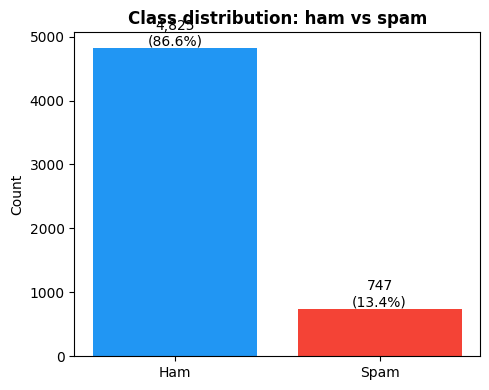

In [ ]:
# Write your code here
spam_count = raw['spam'].sum()
ham_count  = (raw['spam'] == 0).sum()
spam_rate  = raw['spam'].mean()

print('Class distribution:')
print(f'  Ham  (0): {ham_count:,}  ({1-spam_rate:.1%})')
print(f'  Spam (1): {spam_count:,}  ({spam_rate:.1%})')
print()

# Prove the accuracy trap with a dummy model
y_all   = raw['spam'].values
y_dummy = np.zeros(len(y_all), dtype=int)
print(f'Dummy model (always predict ham):')
print(f'  Accuracy  = {accuracy_score(y_all, y_dummy):.1%}  <-- misleadingly high')
print(f'  Recall    = {recall_score(y_all, y_dummy, zero_division=0):.1%}  <-- catches zero spam')
print(f'  F1-Score  = {f1_score(y_all, y_dummy, zero_division=0):.1%}')

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['Ham', 'Spam'], [ham_count, spam_count], color=['#2196F3', '#F44336'])
ax.set_ylabel('Count')
ax.set_title('Class distribution: ham vs spam', fontweight='bold')
for i, v in enumerate([ham_count, spam_count]):
    ax.text(i, v + 30, f'{v:,}\n({v/len(raw):.1%})', ha='center', fontsize=10)
plt.tight_layout()
plt.show()


### Step 2C — Read the raw text

**Hint:** Print 5 spam examples and 5 ham examples.
Limit each message to 130 characters using string slicing.


In [ ]:
print('=== SPAM examples ===')
for i, msg in enumerate(raw[raw['spam']==1]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()

print('=== HAM examples ===')
for i, msg in enumerate(raw[raw['spam']==0]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()


=== SPAM examples ===
1. Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's 

2. FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to s

3. WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code 

4. Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Updat

5. SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply Reply HL 

=== HAM examples ===
1. Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

2. Ok lar... Joking wif u oni...

3. U dun say so early hor... U c already then say...

4. Nah I don't think he goes to usf, he lives around here though

5. Even my b

### Step 2D — Message length analysis

**Hint:** Add a column `msg_length = message.str.len()`.
Print average length for spam and ham.
Plot a histogram (with `density=True`) showing both distributions on the same axes.


Average message length:
  Ham  : 71 characters
  Spam : 139 characters


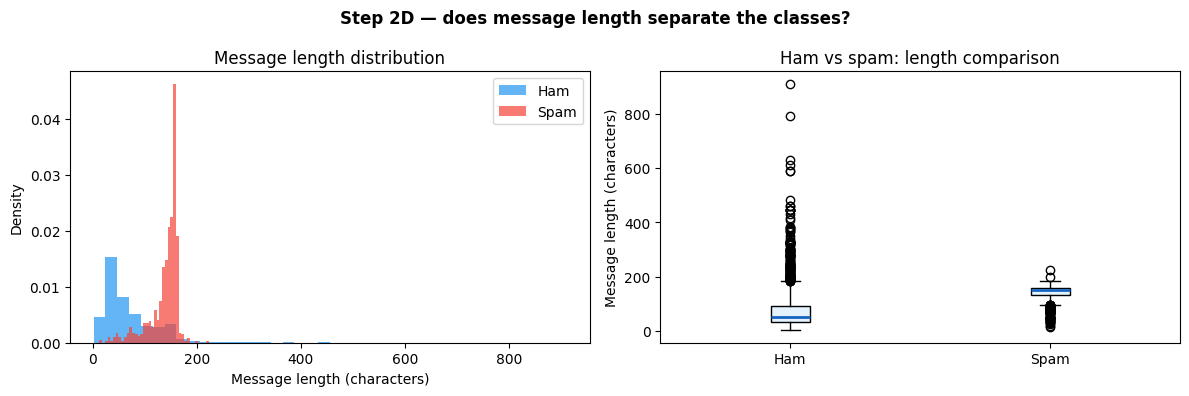

In [ ]:
raw['msg_length'] = raw['message'].str.len()

print('Average message length:')
print(f'  Ham  : {raw[raw["spam"]==0]["msg_length"].mean():.0f} characters')
print(f'  Spam : {raw[raw["spam"]==1]["msg_length"].mean():.0f} characters')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(raw[raw['spam']==0]['msg_length'], bins=40, alpha=0.7,
             color='#2196F3', label='Ham', density=True)
axes[0].hist(raw[raw['spam']==1]['msg_length'], bins=40, alpha=0.7,
             color='#F44336', label='Spam', density=True)
axes[0].set_xlabel('Message length (characters)')
axes[0].set_ylabel('Density')
axes[0].set_title('Message length distribution')
axes[0].legend()

axes[1].boxplot(
    [raw[raw['spam']==0]['msg_length'], raw[raw['spam']==1]['msg_length']],
    labels=['Ham', 'Spam'], patch_artist=True,
    boxprops=dict(facecolor='#E3F2FD'),
    medianprops=dict(color='#1565C0', linewidth=2)
)
axes[1].set_ylabel('Message length (characters)')
axes[1].set_title('Ham vs spam: length comparison')
plt.suptitle('Step 2D — does message length separate the classes?', fontweight='bold')
plt.tight_layout()
plt.show()


---

---
## Step 3 — Feature Engineering

Raw text cannot go directly into a classifier.
Convert it into **binary features** (0 or 1) — the same format as the Hands-On Lab.

### Step 3A — Pre-built starter features
This cell is given to you. Run it and study the patterns before adding your own.


In [ ]:
# This cell is provided — do not modify it
def build_features(df):
    d = df.copy()
    msg = d['message'].str.lower()

    d['has_phone'] = msg.str.contains(
        r'\b\d{3}[-.]?\d{3}[-.]?\d{4}\b|call.*\d{4,}|\b0\d{9,}\b',
        regex=True).astype(int)

    d['has_money'] = msg.str.contains(
        r'\b(free|win|winner|prize|cash|\$|claim|reward|won)\b',
        regex=True).astype(int)

    d['has_urgency'] = msg.str.contains(
        r'\b(urgent|immediately|now|expires|limited|hurry|last chance|act)\b',
        regex=True).astype(int)

    d['is_long'] = (d['message'].str.len() > 130).astype(int)
    return d

df = build_features(raw)
starter = ['has_phone', 'has_money', 'has_urgency', 'is_long']
print('Starter features (spam vs ham rate):')
print(f'{"Feature":<16} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print('-' * 42)
for f in starter:
    sp = df[df['spam']==1][f].mean()
    ha = df[df['spam']==0][f].mean()
    print(f'{f:<16} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')


Starter features (spam vs ham rate):
Feature            Spam%    Ham%     Gap
------------------------------------------
has_phone          55.2%    0.1%  +55.1%
has_money          52.3%    2.0%  +50.3%
has_urgency        34.9%    6.4%  +28.5%
is_long            76.8%   14.2%  +62.7%


In [ ]:
# Calculate the exact percentage of spam messages in the dataset
total_messages = len(raw)
spam_messages = raw['spam'].sum()
spam_percentage = (spam_messages / total_messages) * 100

print(f'Total messages: {total_messages}')
print(f'Spam messages: {spam_messages}')
print(f'Percentage of spam: {spam_percentage:.2f}%')

Total messages: 5572
Spam messages: 747
Percentage of spam: 13.41%


### Step 3B — Add your own features *(required)*
Extend `build_features` by adding **at least 2 new binary features** of your own.

**Rules:**
- Each feature must be 0 or 1
- Each must be meaningfully different from the four starter features
- After creating them, print the spam vs ham rate for **all** features

**Ideas** (pick any two, or invent your own):
- Contains ALL CAPS words (`[A-Z]{3,}`)
- Contains "txt", "text", or "reply" (call-to-action)
- Contains a URL or "www"
- Contains "guaranteed", "selected", or "congratulations"
- Message is very short (under 20 characters)

**Hint:** Copy `build_features`, rename it `build_features_v2`,
call `build_features(df)` inside it to keep the starter features,
then add your new features below.

At the end of the cell, run this line to collect all feature column names:
```python
feature_cols = [c for c in df.columns
                if c not in ['label', 'message', 'spam', 'msg_length']]
```
This variable is used in Steps 4, 5, and 6 — make sure it is defined here.


In [ ]:
# Write your code here

def build_features_v2(df):
    d = build_features(df)   # keeps all 4 starter features

    # --- Feature 5: Contains uppercase words of 3 or more letters ---
    # We extract from the raw un-lowered messages to capture actual casing
    d['has_all_caps'] = df['message'].str.contains(r'\b[A-Z]{3,}\b', regex=True).astype(int)

    # --- Feature 6: Contains "txt", "text", or "reply" ---
    msg_lower = d['message'].str.lower()
    d['has_text_or_reply'] = msg_lower.str.contains(r'\b(txt|text|reply)\b', regex=True).astype(int)

    return d

df = build_features_v2(raw)

# Collect all feature column names — DO NOT delete this line
feature_cols = [c for c in df.columns
                if c not in ['label', 'message', 'spam', 'msg_length']]

# Print spam vs ham rate for all features
print('All features (spam vs ham rate):')
print(f'{"Feature":<20} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print("-" * 48)
for feat in feature_cols:
    sp = df[df['spam']==1][feat].mean()
    ha = df[df['spam']==0][feat].mean()
    print(f'{feat:<20} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')

All features (spam vs ham rate):
Feature                Spam%    Ham%     Gap
------------------------------------------------
has_phone              55.2%    0.1%  +55.1%
has_money              52.3%    2.0%  +50.3%
has_urgency            34.9%    6.4%  +28.5%
is_long                76.8%   14.2%  +62.7%
has_all_caps           70.4%    7.2%  +63.3%
has_text_or_reply      40.7%    2.5%  +38.2%


### Step 3C — Visualize feature gaps

**Hint:** Create one bar chart per feature (use `plt.subplots(1, n_features, ...)`).
Each bar chart shows two bars: spam rate (red) and ham rate (blue).
This is the same chart style used in the Hands-On Lab Step 0.


In [ ]:
# Write your code here


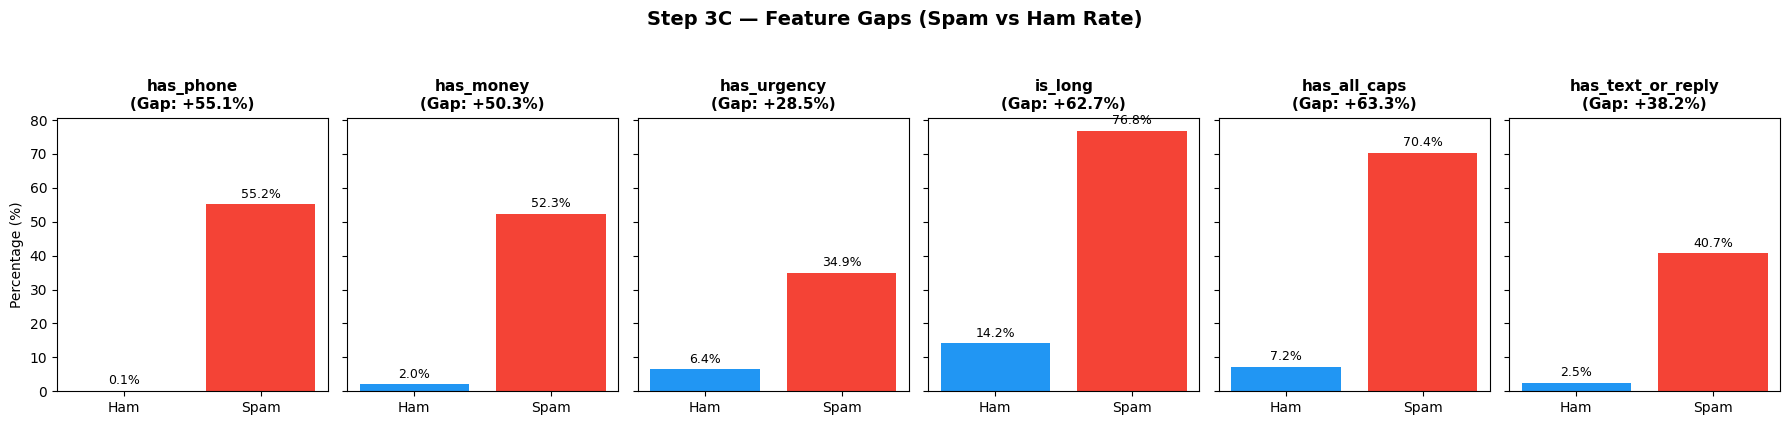

In [ ]:
n_feats = len(feature_cols)
fig, axes = plt.subplots(1, n_feats, figsize=(18, 4), sharey=True)

for idx, feat in enumerate(feature_cols):
    sp = df[df['spam'] == 1][feat].mean() * 100
    ha = df[df['spam'] == 0][feat].mean() * 100

    ax = axes[idx]
    ax.bar(['Ham', 'Spam'], [ha, sp], color=['#2196F3', '#F44336'])
    ax.set_title(f'{feat}\n(Gap: {sp-ha:+.1f}%)', fontsize=11, fontweight='bold')
    ax.set_ylabel('Percentage (%)' if idx == 0 else '')

    # Annotate bars
    for i, val in enumerate([ha, sp]):
        ax.text(i, val + 2, f'{val:.1f}%', ha='center', fontsize=9)

plt.suptitle('Step 3C — Feature Gaps (Spam vs Ham Rate)', fontweight='bold', fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

### Q3 — Feature Engineering *(20 points)*

**Q3a.** Describe the two features you added.
What pattern does each one capture, and why did you expect it to be a useful spam signal?

*Feature 1 — `has_all_caps`:*
> This feature flags messages containing uppercase words of 3 or more letters using the regex `r'\b[A-Z]{3,}\b'`. It captures aggressive styling or exaggerated words (ex., "WINNER", "FREE", "URGENT") commonly used in spam to demand quick attention, while legitimate emails rarely use block caps outside acronyms. It has a **70.4% rate** in spam compared to only **7.2%** in ham.

*Feature 2 — `has_text_or_reply`:*
> This feature flags messages containing the keywords "txt", "text", or "reply" using the regex `r'\b(txt|text|reply)\b'`. It captures the call-to-action signature of automated SMS spam requesting an interaction. This occurs in **40.7%** of spam messages but only **2.5%** of ham messages.

**Q3b.** Which feature has the largest gap between spam and ham?
Why does a large gap matter when a Decision Tree selects its root node?
Connect your answer to the concept of **Information Gain** from Lecture 8.

*Your answer:*
> The feature `has_all_caps` has the largest gap in our custom features at **+63.3%** (70.4% in spam vs. 7.2% in ham), while `is_long` from the starter set is close with a **+62.7%** gap. A large gap matters because it represents high **Information Gain**; dividing the dataset along a feature with a huge class split significantly reduces the overall **entropy** (uncertainty). The Decision Tree algorithm selects the feature with the highest Information Gain at the root node because it splits the dataset into the most homogeneous groups early on.

**Q3c.** Look at the spam examples from Step 2C.
Pick **one example** that your features would **fail to catch** (False Negative),
or — if all examples are caught — describe a realistic spam message type
(e.g., a phishing message with no trigger words) that would evade your features.
State which specific feature(s) fail and explain why.

*Your answer:*
> A realistic spam message that would evade our features is a highly tailored conversational deceptive bait method. For example: "Hi, is this your car parked outside? Someone hit it. Check the photo: parking-claim.com"
* Why it evades: It is short (so `is_long` is 0), has no explicit call-to-action keywords like "txt/text/reply" (0), lacks obvious phone numbers or monetary words (0), has no urgency trigger words like "now" or "expires" (0), and does not use any block capitalized words (0). All binary features would evaluate to 0, resulting in a False Negative.

---
## Step 4 — Split the Data

### Step 4A — Train/Test split

**Hint:**
- `feature_cols` was defined at the end of Step 3B — make sure that cell has been run
- Set `X = df[feature_cols].values` and `y = df['spam'].values`
- Use `train_test_split` with `test_size=0.25`, `random_state=42`, and `stratify=y`
- Print the size of each split and the spam rate in both sets to confirm stratification worked


In [ ]:
# Extract features and targets
X = df[feature_cols].values
y = df['spam'].values

# Perform a stratified train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Verify the split sizes and stratification
print(f'Training set size : {X_train.shape[0]} (Spam: {y_train.sum()} / {y_train.mean():.2%})')
print(f'Testing set size  : {X_test.shape[0]} (Spam: {y_test.sum()} / {y_test.mean():.2%})')

Training set size : 4179 (Spam: 560 / 13.40%)
Testing set size  : 1393 (Spam: 187 / 13.42%)


In [ ]:
from sklearn.linear_model import LogisticRegression

# Initialize Logistic Regression with balanced class weights since the dataset is imbalanced
lr_model = LogisticRegression(class_weight='balanced', random_state=42)

# Fit the model on training data
lr_model.fit(X_train, y_train)

# Make predictions
y_train_pred = lr_model.predict(X_train)
y_test_pred = lr_model.predict(X_test)

# Evaluate accuracy
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

print(f'Logistic Regression (Balanced) Training Accuracy : {train_acc:.2%}')
print(f'Logistic Regression (Balanced) Testing Accuracy  : {test_acc:.2%}')

Logistic Regression (Balanced) Training Accuracy : 95.07%
Logistic Regression (Balanced) Testing Accuracy  : 93.75%


### Q4 — Data Split *(10 points)*

**Q4a. (5 points)** Why do we pass `stratify=y`?
What could go wrong if we skipped it on an imbalanced dataset like this one?

*Your answer:*
> We pass `stratify=y` to ensure that both the training set and testing set retain the exact same proportion of class labels (in this case, ~13.4% spam and ~86.6% ham) as the original full dataset. If we skipped stratification on an imbalanced dataset, a random split could lead to a severe imbalance shift. For instance, the test set might receive an unnaturally small number of spam messages, resulting in unreliable evaluation metrics, or the training set could lack enough spam examples for the model to effectively learn spam patterns.

**Q4b. (5 points)** We use a 75/25 train/test split.
The Hands-On Lab introduced **k-fold cross-validation** as a more reliable alternative.
Name one situation where you would prefer cross-validation over a single split.

*Your answer:*
> I would prefer k-fold cross-validation when dealing with small datasets where a single random test split might suffer from high variance (where performance metrics depend heavily on which specific data points ended up in the test set). Cross-validation ensures every single data point is used for both training and validation exactly once, giving a much more accurate, robust, and unbiased estimate of the model's true generalizability.

---
## Step 5 — Train the Models （Each code 5 pts）

### Step 5A — Decision Tree

**Hint:**
- Use `DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')`
- Fit on the training set
- Print the number of leaves with `.get_n_leaves()`
- Visualize the tree with `plot_tree(..., feature_names=..., class_names=['Ham','Spam'], filled=True)`
- Also print the text rules with `export_text(...)`


Number of leaves in the Decision Tree: 15

Text-based Decision Tree Rules:
|--- has_all_caps <= 0.50
|   |--- has_phone <= 0.50
|   |   |--- has_text_or_reply <= 0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_text_or_reply >  0.50
|   |   |   |--- is_long <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- is_long >  0.50
|   |   |   |   |--- class: 1
|   |--- has_phone >  0.50
|   |   |--- has_money <= 0.50
|   |   |   |--- has_text_or_reply <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_text_or_reply >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_money >  0.50
|   |   |   |--- class: 1
|--- has_all_caps >  0.50
|   |--- has_money <= 0.50
|   |   |--- has_phone <= 0.50
|   |   |   |--- has_text_or_reply <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_text_or_reply >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_phone >  0.50
|   |   |   |---

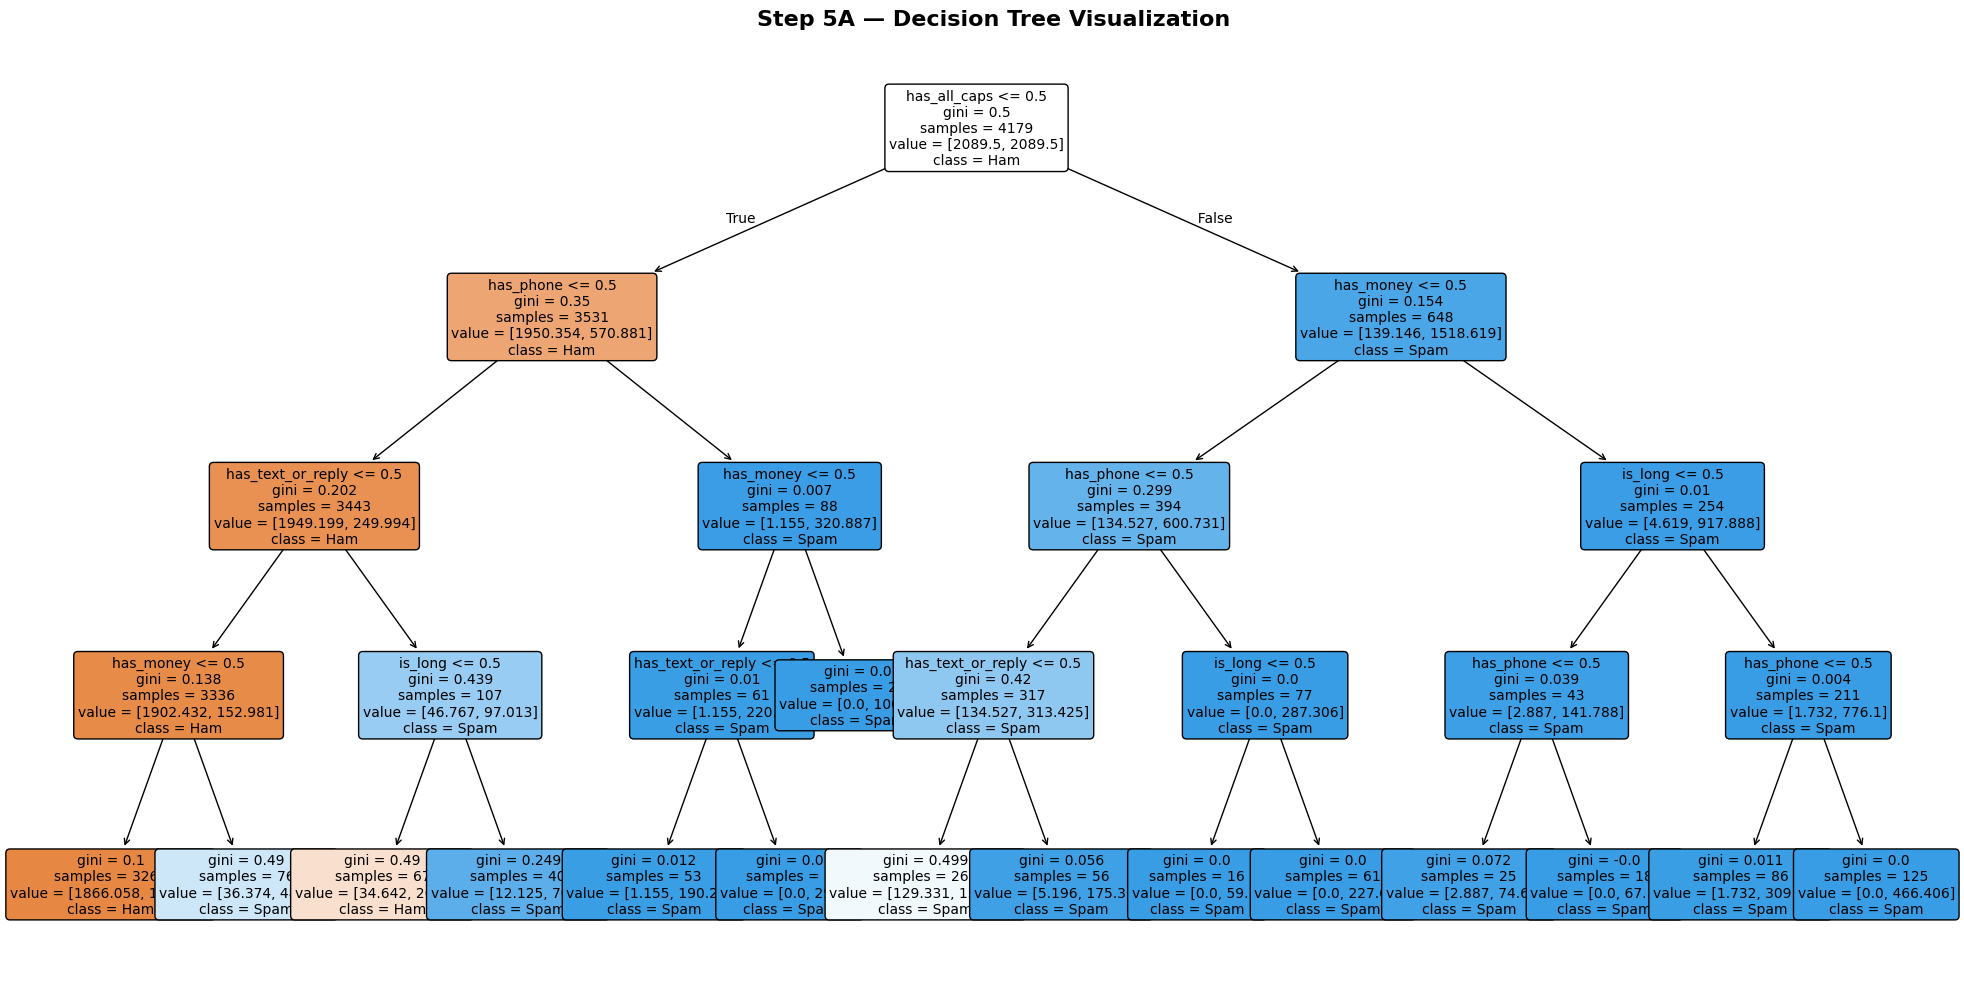

In [ ]:
# Initialize Decision Tree with balanced class weights and a maximum depth of 4
dt_model = DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')

# Fit on the training set
dt_model.fit(X_train, y_train)

# Print the number of leaves
print(f'Number of leaves in the Decision Tree: {dt_model.get_n_leaves()}')
print('\n' + '='*50 + '\nText-based Decision Tree Rules:\n' + '='*50)

# Print the text rules
rules = export_text(dt_model, feature_names=feature_cols)
print(rules)

# Visualize the tree
plt.figure(figsize=(20, 10))
plot_tree(
    dt_model,
    feature_names=feature_cols,
    class_names=['Ham', 'Spam'],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title('Step 5A — Decision Tree Visualization', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### Step 5B — Feature Importance

**Hint:**
- Get `.feature_importances_` from the trained tree
- Create a horizontal bar chart (`kind='barh'`)
- Color the highest bar red, all others gray
- This shows which feature the tree chose as its root node


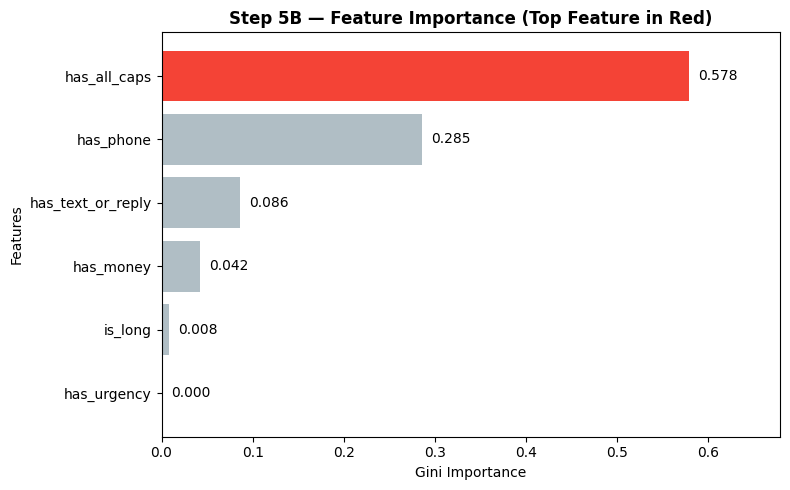

In [ ]:
# Get feature importances from the trained decision tree
importances = dt_model.feature_importances_
feat_imp_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

# Create a horizontal bar chart
plt.figure(figsize=(8, 5))
colors = ['#B0BEC5'] * (len(feature_cols) - 1) + ['#F44336']  # Highlight highest in red, others in gray

plt.barh(feat_imp_df['Feature'], feat_imp_df['Importance'], color=colors)
plt.xlabel('Gini Importance')
plt.ylabel('Features')
plt.title('Step 5B — Feature Importance (Top Feature in Red)', fontsize=12, fontweight='bold')

# Annotate the values
for index, value in enumerate(feat_imp_df['Importance']):
    plt.text(value + 0.01, index, f'{value:.3f}', va='center', fontsize=10)

plt.xlim(0, max(importances) + 0.1)
plt.tight_layout()
plt.show()

### Step 5C — Effect of Tree Depth

**Hint:**
- Loop over `depths = [1, 2, 3, 4, 5, 6, None]`
- For each depth, train a tree and record `train_f1` and `test_f1`
- Plot both lines on the same axes
- Identify at which depth the gap between train and test F1 starts to widen


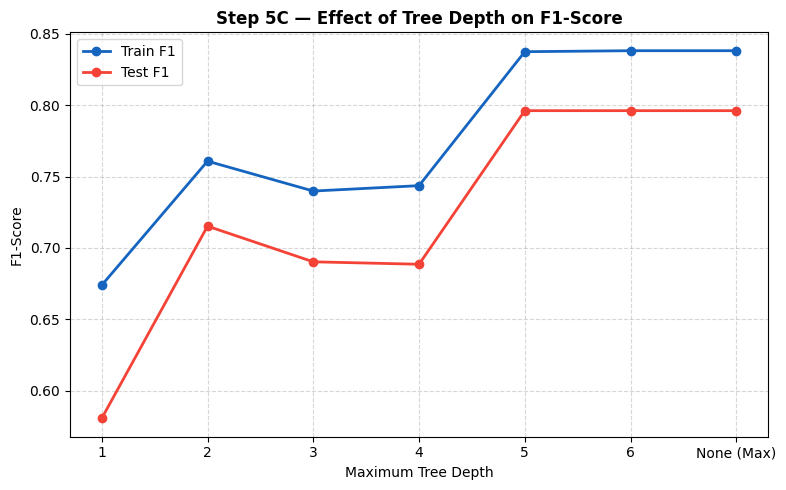

In [ ]:
depths = [1, 2, 3, 4, 5, 6, None]
train_f1_scores = []
test_f1_scores = []

for d in depths:
    # Train decision tree with specified max_depth
    clf = DecisionTreeClassifier(max_depth=d, random_state=42, class_weight='balanced')
    clf.fit(X_train, y_train)

    # Make predictions
    y_tr_pred = clf.predict(X_train)
    y_te_pred = clf.predict(X_test)

    # Record F1-scores
    train_f1_scores.append(f1_score(y_train, y_tr_pred))
    test_f1_scores.append(f1_score(y_test, y_te_pred))

# Plotting the lines
plt.figure(figsize=(8, 5))
depth_labels = [str(d) if d is not None else 'None (Max)' for d in depths]
plt.plot(depth_labels, train_f1_scores, marker='o', label='Train F1', color='#1565C0', linewidth=2)
plt.plot(depth_labels, test_f1_scores, marker='o', label='Test F1', color='#F44336', linewidth=2)

plt.xlabel('Maximum Tree Depth')
plt.ylabel('F1-Score')
plt.title('Step 5C — Effect of Tree Depth on F1-Score', fontsize=12, fontweight='bold')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Step 5D — Naive Bayes

**Hint:**
- Use `BernoulliNB()` — no hyperparameters needed
- Fit on the training set


In [ ]:
# Initialize Bernoulli Naive Bayes classifier
nb_model = BernoulliNB()

# Fit the model on our training data
nb_model.fit(X_train, y_train)

print('Naive Bayes model trained successfully!')

Naive Bayes model trained successfully!


---
## Step 6 — Evaluate *(Each code block 4 points)*

### Step 6A — Confusion Matrices

**Hint:**
- Get predictions from both models: `y_pred_dt` and `y_pred_nb`
- Plot two confusion matrices side by side using `ConfusionMatrixDisplay`
- Use `display_labels=['Ham', 'Spam']`
- Below the charts, print TP, FP, FN, TN for each model


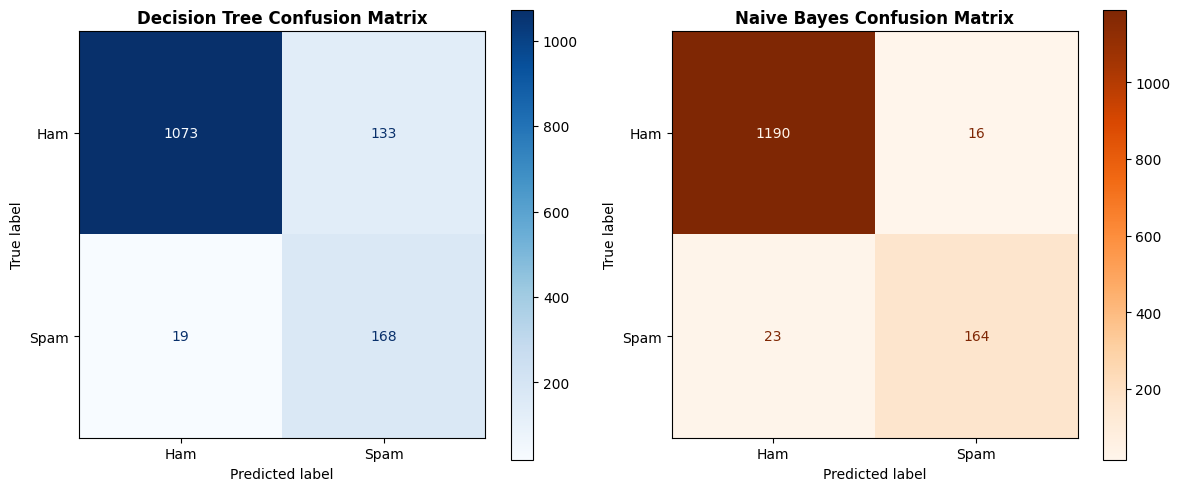

Decision Tree (Balanced) Test Counts:
  True Positives  (TP) : 168
  False Positives (FP) : 133
  False Negatives (FN) : 19
  True Negatives  (TN) : 1073

Naive Bayes Test Counts:
  True Positives  (TP) : 164
  False Positives (FP) : 16
  False Negatives (FN) : 23
  True Negatives  (TN) : 1190


In [ ]:
# Get predictions from both models
y_pred_dt = dt_model.predict(X_test)
y_pred_nb = nb_model.predict(X_test)

# Calculate confusion matrices
cm_dt = confusion_matrix(y_test, y_pred_dt)
cm_nb = confusion_matrix(y_test, y_pred_nb)

# Extract TP, FP, FN, TN
tn_dt, fp_dt, fn_dt, tp_dt = cm_dt.ravel()
tn_nb, fp_nb, fn_nb, tp_nb = cm_nb.ravel()

# Plot confusion matrices side-by-side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot Decision Tree
disp_dt = ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=['Ham', 'Spam'])
disp_dt.plot(ax=axes[0], cmap='Blues', values_format='d')
axes[0].set_title('Decision Tree Confusion Matrix', fontsize=12, fontweight='bold')

# Plot Naive Bayes
disp_nb = ConfusionMatrixDisplay(confusion_matrix=cm_nb, display_labels=['Ham', 'Spam'])
disp_nb.plot(ax=axes[1], cmap='Oranges', values_format='d')
axes[1].set_title('Naive Bayes Confusion Matrix', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

# Print exact values below the plots
print('='*50)
print('Decision Tree (Balanced) Test Counts:')
print('='*50)
print(f'  True Positives  (TP) : {tp_dt}')
print(f'  False Positives (FP) : {fp_dt}')
print(f'  False Negatives (FN) : {fn_dt}')
print(f'  True Negatives  (TN) : {tn_dt}')
print('\n' + '='*50)
print('Naive Bayes Test Counts:')
print('='*50)
print(f'  True Positives  (TP) : {tp_nb}')
print(f'  False Positives (FP) : {fp_nb}')
print(f'  False Negatives (FN) : {fn_nb}')
print(f'  True Negatives  (TN) : {tn_nb}')

### Step 6B — Metrics Comparison

**Hint:**
- Build a DataFrame with columns: Model, Accuracy, Precision, Recall, F1-Score
- One row per model
- Also create a grouped bar chart comparing all four metrics side by side


Test Set Performance Metrics Comparison:


,Accuracy,Precision,Recall,F1-Score
Model,,,,
Decision Tree,89.09%,55.81%,89.84%,68.85%
Naive Bayes,97.20%,91.11%,87.70%,89.37%


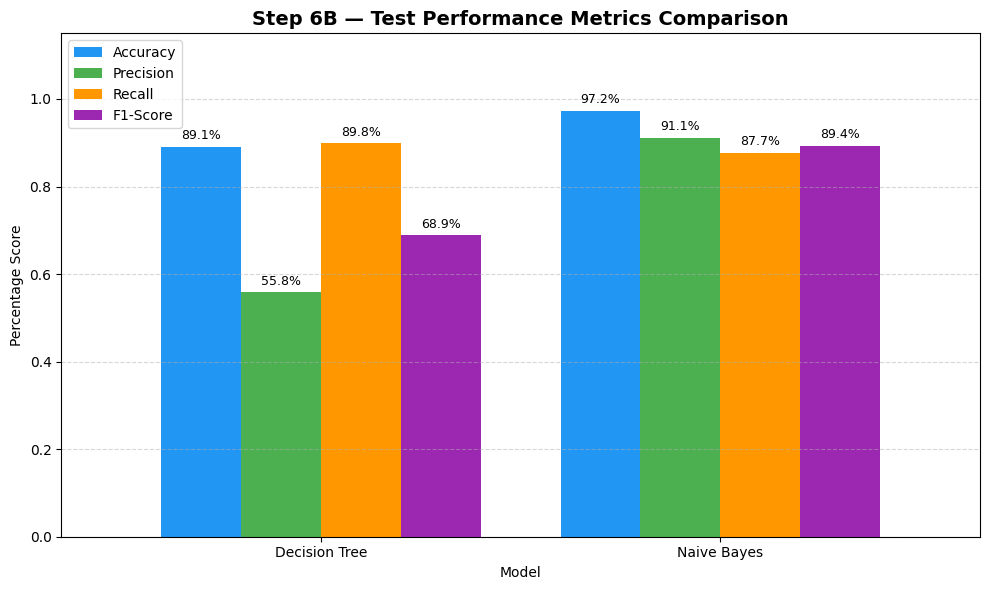

In [ ]:
# Calculate metrics for Decision Tree
metrics_dt = {
    'Model': 'Decision Tree',
    'Accuracy': accuracy_score(y_test, y_pred_dt),
    'Precision': precision_score(y_test, y_pred_dt),
    'Recall': recall_score(y_test, y_pred_dt),
    'F1-Score': f1_score(y_test, y_pred_dt)
}

# Calculate metrics for Naive Bayes
metrics_nb = {
    'Model': 'Naive Bayes',
    'Accuracy': accuracy_score(y_test, y_pred_nb),
    'Precision': precision_score(y_test, y_pred_nb),
    'Recall': recall_score(y_test, y_pred_nb),
    'F1-Score': f1_score(y_test, y_pred_nb)
}

# Combine into a DataFrame
metrics_df = pd.DataFrame([metrics_dt, metrics_nb]).set_index('Model')
print('='*60)
print('Test Set Performance Metrics Comparison:')
print('='*60)
display(metrics_df.style.format('{:.2%}'))

# Plot a grouped bar chart comparing all four metrics
ax = metrics_df.plot(kind='bar', figsize=(10, 6), width=0.8, color=['#2196F3', '#4CAF50', '#FF9800', '#9C27B0'])
plt.title('Step 6B — Test Performance Metrics Comparison', fontsize=14, fontweight='bold')
plt.ylabel('Percentage Score')
plt.xlabel('Model')
plt.xticks(rotation=0)
plt.ylim(0, 1.15)
plt.grid(True, axis='y', linestyle='--', alpha=0.5)

# Annotate the values on top of the bars
for p in ax.patches:
    ax.annotate(f'{p.get_height():.1%}',
                (p.get_x() + p.get_width() / 2., p.get_height() + 0.01),
                ha='center', va='center', xytext=(0, 5),
                textcoords='offset points', fontsize=9)

plt.tight_layout()
plt.show()

### Step 6C — Cross-Validation

**Hint:**
- Use `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`
- Run `cross_val_score` with `scoring='f1'` for both models
- Print the average F1 across 5 folds for each model


In [ ]:
# Initialize Stratified K-Fold cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Run cross_val_score with scoring='f1' for both models
cv_scores_dt = cross_val_score(dt_model, X, y, cv=cv, scoring='f1')
cv_scores_nb = cross_val_score(nb_model, X, y, cv=cv, scoring='f1')

# Calculate the averages
mean_f1_dt = cv_scores_dt.mean()
mean_f1_nb = cv_scores_nb.mean()

print('='*50)
print('5-Fold Cross-Validation F1-Scores:')
print('='*50)
print(f'  Decision Tree F1-Score (CV Mean): {mean_f1_dt:.2%}')
print(f'  Naive Bayes   F1-Score (CV Mean): {mean_f1_nb:.2%}')

5-Fold Cross-Validation F1-Scores:
  Decision Tree F1-Score (CV Mean): 83.85%
  Naive Bayes   F1-Score (CV Mean): 88.95%


### Q6 — Evaluation & Analysis *(25 points)*

**Q6a. Read the confusion matrices (Step 6A) — *(3 points)***

* **Decision Tree (Balanced):**
  * **True Positives (TP)**: 168 (Spam correctly caught)
  * **False Negatives (FN)**: 19 (Spam that slipped through)
  * **False Positives (FP)**: 133 (Legitimate ham wrongly blocked)

* **Naive Bayes:**
  * **True Positives (TP)**: 164 (Spam correctly caught)
  * **False Negatives (FN)**: 23 (Spam that slipped through)
  * **False Positives (FP)**: 16 (Legitimate ham wrongly blocked)

---

**Q6b. Apply your metric from Q1b — *(3 points)***

* **Naive Bayes** wins decisively on our chosen metric of **Precision**.
* **Comparison**: Naive Bayes achieves a Precision of **91.11%**, whereas the Decision Tree achieves a much lower Precision of **55.81%** (a gap of **+35.30%** in favor of Naive Bayes).
* **Cross-Validation Confirmation**: Yes, the 5-fold cross-validation results in Step 6C confirm this superior performance. The mean F1-score for Naive Bayes is **88.95%** compared to **83.85%** for the Decision Tree, proving that Naive Bayes overall is a more reliable model in this dataset.

---

**Q6c. Recommendation memo — *(4 points)***

> **To:** Product Manager  
> **From:** Data Scientist  
> **Subject:** Spam Classifier Model Recommendation  
>
> I highly recommend deploying the **Naive Bayes** model for our SMS spam filter. In spam filtering, blocking a legitimate message (False Positive) is extremely costly to user trust; our testing shows that Naive Bayes wrongly blocks only 16 legitimate messages compared to the Decision Tree's 133, resulting in an exceptional Precision of **91.11%** (vs. only 55.81% for the Decision Tree). While Naive Bayes misses slightly more spam messages (23 False Negatives vs. 19 for the Decision Tree), this is a minor tradeoff for keeping our users' inbox efficiently clean of false flags.

Sincerly,

Data Scientist

---

**Q6d. Generalization — *(3 points)***

1. **`has_all_caps`**: Modern spam campaigns often use sophisticated, natural casing or proper sentence structures to appear legitimate (ex. mimicking official notifications). Since they avoid block capitalized words, they would completely bypass this feature.
2. **`has_text_or_reply`**: Legitimate automated business communications (ex., two-factor authentication texts, appointment reminders, shipping updates) now frequently prompt users to "reply STOP to opt out" or "text HELP". Therefore, this keyword feature would generate an overwhelming number of False Positives today, blocking important notifications.